In [243]:
import csv
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from boruta import BorutaPy
from sklearn.svm import SVR
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

In [244]:
df = pd.read_csv('1-POWER_Point_Hourly_20230101_20240101_029d20N_032d62E_UTC.csv')
df2 = pd.read_csv('2-POWER_Point_Hourly_20230101_20240101_029d20N_032d62E_UTC.csv')
df2

,YEAR,MO,DY,HR,WD50M,WS50M,WD10M
0,2023,1,1,0,356.17,6.20,354.44
1,2023,1,1,1,345.75,6.16,344.21
2,2023,1,1,2,338.11,6.26,336.47
3,2023,1,1,3,334.91,6.26,333.58
4,2023,1,1,4,334.66,6.04,334.07
...,...,...,...,...,...,...,...
8779,2024,1,1,19,343.50,7.18,342.36
8780,2024,1,1,20,349.89,7.12,348.96
8781,2024,1,1,21,351.60,7.06,350.63
8782,2024,1,1,22,349.97,6.86,349.22


In [245]:
df['All Sky Surface Shortwave Downward Irradiance'] = df['ALLSKY_SFC_SW_DWN']
df['Clear Sky Surface Shortwave Downward Irradiance'] = df['CLRSKY_SFC_SW_DWN']
df['All Sky Surface Shortwave Downward Direct Normal Irradiance'] = df['ALLSKY_SFC_SW_DNI']
df['All Sky Surface Shortwave Diffuse Irradiance'] = df['ALLSKY_SFC_SW_DIFF']
df['All Sky Insolation Clearness Index'] = df['ALLSKY_KT']
df['All Sky Surface Albedo'] = df['ALLSKY_SRF_ALB']
df['Solar Zenith Angle'] = df['SZA']
df['All Sky Surface PAR Total'] = df['ALLSKY_SFC_PAR_TOT']
df['Clear Sky Surface PAR Total'] = df['CLRSKY_SFC_PAR_TOT']
df['All Sky Surface UVA Irradiance'] = df['ALLSKY_SFC_UVA']
df['All Sky Surface UVB Irradiance'] = df['ALLSKY_SFC_UVB']
df['All Sky Surface UV Index'] = df['ALLSKY_SFC_UV_INDEX']
df['Temperature at 2 Meters'] = df['T2M']
df['Frost Point at 2 Meters'] = df['T2MDEW']
df['Wet Bulb Temperature at 2 Meters'] = df['T2MWET']
df['Specific Humidity at 2 Meters'] = df['QV2M']
df['Relative Humidity at 2 Meters'] = df['RH2M']
df['Precipitation Corrected'] = df['PRECTOTCORR']
df['Surface Pressure'] = df['PS']
df['Wind Speed at 10 Meters'] = df['WS10M']

df['Wind Direction at 50 Meters'] = df2['WD50M']
df['Wind Speed at 50 Meters'] = df2['WS50M']
df['Wind Direction at 10 Meters'] = df2['WD10M']

df = df.drop(columns=['ALLSKY_SFC_SW_DWN', 'CLRSKY_SFC_SW_DWN', 'ALLSKY_SFC_SW_DNI', 'ALLSKY_SFC_SW_DIFF', 'ALLSKY_KT', 'ALLSKY_SRF_ALB', 'SZA', 'ALLSKY_SFC_PAR_TOT', 'CLRSKY_SFC_PAR_TOT', 'ALLSKY_SFC_UVA', 'ALLSKY_SFC_UVB', 'ALLSKY_SFC_UV_INDEX', 'T2M', 'T2MDEW', 'T2MWET', 'QV2M', 'RH2M', 'PRECTOTCORR', 'PS', 'WS10M'])

In [246]:
df.replace(-999, 0, inplace=True)
df

,YEAR,MO,DY,HR,All Sky Surface Shortwave Downward Irradiance,Clear Sky Surface Shortwave Downward Irradiance,All Sky Surface Shortwave Downward Direct Normal Irradiance,All Sky Surface Shortwave Diffuse Irradiance,All Sky Insolation Clearness Index,All Sky Surface Albedo,...,Frost Point at 2 Meters,Wet Bulb Temperature at 2 Meters,Specific Humidity at 2 Meters,Relative Humidity at 2 Meters,Precipitation Corrected,Surface Pressure,Wind Speed at 10 Meters,Wind Direction at 50 Meters,Wind Speed at 50 Meters,Wind Direction at 10 Meters
0,2023,1,1,0,0.0,0.0,0.0,0.0,0.0,0.0,...,10.08,10.92,7.81,89.38,0.01,98.68,4.03,356.17,6.20,354.44
1,2023,1,1,1,0.0,0.0,0.0,0.0,0.0,0.0,...,10.32,11.01,7.93,91.12,0.01,98.63,4.02,345.75,6.16,344.21
2,2023,1,1,2,0.0,0.0,0.0,0.0,0.0,0.0,...,10.50,10.91,8.06,94.81,0.01,98.61,4.09,338.11,6.26,336.47
3,2023,1,1,3,0.0,0.0,0.0,0.0,0.0,0.0,...,10.56,10.86,8.12,96.38,0.01,98.63,4.20,334.91,6.26,333.58
4,2023,1,1,4,0.0,0.0,0.0,0.0,0.0,0.0,...,10.55,10.87,8.12,96.06,0.01,98.66,4.45,334.66,6.04,334.07
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8779,2024,1,1,19,0.0,0.0,0.0,0.0,0.0,0.0,...,11.08,12.79,8.42,80.25,0.00,98.64,4.62,343.50,7.18,342.36
8780,2024,1,1,20,0.0,0.0,0.0,0.0,0.0,0.0,...,11.10,12.67,8.42,81.56,0.00,98.64,4.61,349.89,7.12,348.96
8781,2024,1,1,21,0.0,0.0,0.0,0.0,0.0,0.0,...,11.03,12.44,8.36,83.19,0.00,98.63,4.61,351.60,7.06,350.63
8782,2024,1,1,22,0.0,0.0,0.0,0.0,0.0,0.0,...,11.08,12.20,8.36,86.19,0.00,98.61,4.51,349.97,6.86,349.22


In [247]:
df.columns

Index(['YEAR', 'MO', 'DY', 'HR',
       'All Sky Surface Shortwave Downward Irradiance',
       'Clear Sky Surface Shortwave Downward Irradiance',
       'All Sky Surface Shortwave Downward Direct Normal Irradiance',
       'All Sky Surface Shortwave Diffuse Irradiance',
       'All Sky Insolation Clearness Index', 'All Sky Surface Albedo',
       'Solar Zenith Angle', 'All Sky Surface PAR Total',
       'Clear Sky Surface PAR Total', 'All Sky Surface UVA Irradiance',
       'All Sky Surface UVB Irradiance', 'All Sky Surface UV Index',
       'Temperature at 2 Meters', 'Frost Point at 2 Meters',
       'Wet Bulb Temperature at 2 Meters', 'Specific Humidity at 2 Meters',
       'Relative Humidity at 2 Meters', 'Precipitation Corrected',
       'Surface Pressure', 'Wind Speed at 10 Meters',
       'Wind Direction at 50 Meters', 'Wind Speed at 50 Meters',
       'Wind Direction at 10 Meters'],
      dtype='object')

### Anova Feature Selection

Selected feature names: ['Temperature at 2 Meters', 'Wind Speed at 10 Meters', 'Relative Humidity at 2 Meters', 'Surface Pressure', 'DY']
the number of features:  5


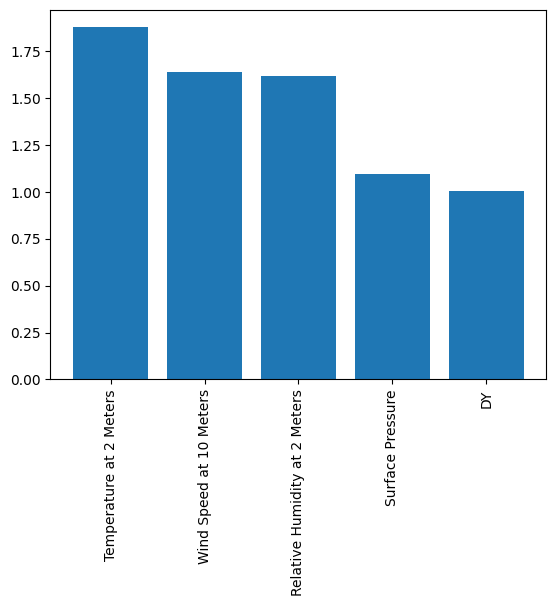

In [248]:
X = df.drop(columns=['All Sky Surface Shortwave Downward Irradiance', 'Clear Sky Surface Shortwave Downward Irradiance', 
                     'All Sky Surface Shortwave Downward Direct Normal Irradiance', 'All Sky Surface Shortwave Diffuse Irradiance',
                     'All Sky Surface PAR Total', 'Clear Sky Surface PAR Total', 'All Sky Surface UVA Irradiance',
                     'All Sky Surface UVB Irradiance', 'All Sky Surface UV Index', 'All Sky Surface Albedo','Solar Zenith Angle',
                     'All Sky Insolation Clearness Index', 'Wind Direction at 50 Meters', 'Wind Speed at 50 Meters',
                     'Precipitation Corrected','Specific Humidity at 2 Meters','Wet Bulb Temperature at 2 Meters',
                     'Frost Point at 2 Meters', 'MO'])
y = df['All Sky Surface Shortwave Downward Irradiance']

selector = SelectKBest(f_classif, k=5)  # Select top 10 features
X_new = selector.fit_transform(X, y)
scores = selector.scores_
selected_feature_indices = selector.get_support(indices=True)
selected_features_with_scores = [(X.columns[i], scores[i]) for i in selected_feature_indices]
selected_features_with_scores.sort(key=lambda x: x[1], reverse=True)
sorted_selected_feature_names = [feature[0] for feature in selected_features_with_scores]
#selected_feature_names = X.columns[selected_feature_indices]
print("Selected feature names:", sorted_selected_feature_names)
print("the number of features: ", len(sorted_selected_feature_names))

plt.bar([feature[0] for feature in selected_features_with_scores], [feature[1] for feature in selected_features_with_scores])
plt.xticks(rotation=90)
plt.show()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)

### Boruta Feature Selection

Boruta Ranking:  [2 1 1 1 1 1 1 1 1]
No. of significant features:  8


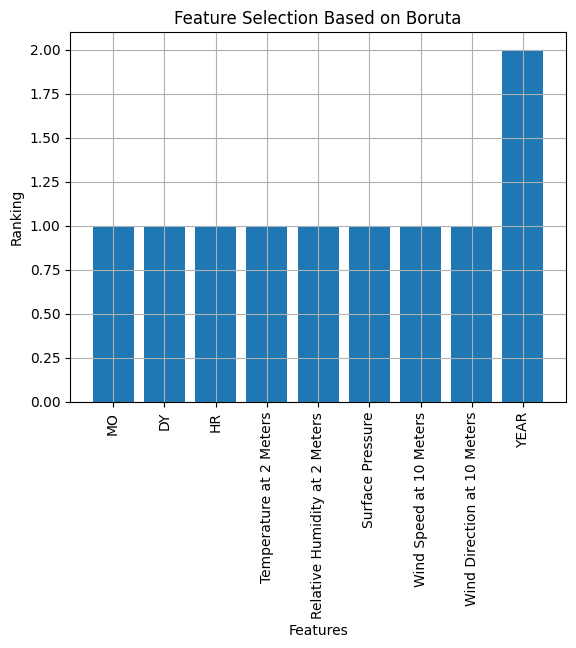

In [7]:
model = RandomForestRegressor()
boruta_selector = BorutaPy(model, n_estimators='auto', verbose=0, random_state=1, max_iter=100)
boruta_selector.fit(X.values, y.values)
print("Boruta Ranking: ", boruta_selector.ranking_)
print("No. of significant features: ", boruta_selector.n_features_)
selected_rf_features = pd.DataFrame({
    'Feature': list(X.columns),
    'Ranking': boruta_selector.ranking_
}).sort_values(by='Ranking')
# Selecting the columns with ranking 1
new_columns = selected_rf_features[selected_rf_features["Ranking"] == 1]['Feature']
X_new = X[new_columns]

plt.bar(selected_rf_features['Feature'], selected_rf_features['Ranking'])
plt.xticks(rotation=90)
plt.grid()
plt.title("Feature Selection Based on Boruta")
plt.xlabel("Features")
plt.ylabel("Ranking")
plt.show()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)

In [249]:
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f'MSE: {mse}')
print(f'RMSE: {rmse}')
print(f'R2: {r2}')
print(f'MAE: {mae}')

MSE: 43417.57525358485
RMSE: 208.36884424881003
R2: 0.5981319383644794
MAE: 171.24970060859746


In [250]:
gb = GradientBoostingRegressor()
gb.fit(X_train, y_train)
y_pred = gb.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f'MSE: {mse}')
print(f'RMSE: {rmse}')
print(f'R2: {r2}')
print(f'MAE: {mae}')

MSE: 3704.4875710045903
RMSE: 60.86450173134247
R2: 0.9657116909266007
MAE: 38.45950986781753


In [251]:
dt = DecisionTreeRegressor()
dt.fit(X_train, y_train)
y_pred = dt.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f'MSE: {mse}')
print(f'RMSE: {rmse}')
print(f'R2: {r2}')
print(f'MAE: {mae}')

MSE: 5413.585846243597
RMSE: 73.57707418920378
R2: 0.9498924746989924
MAE: 35.380930563460446


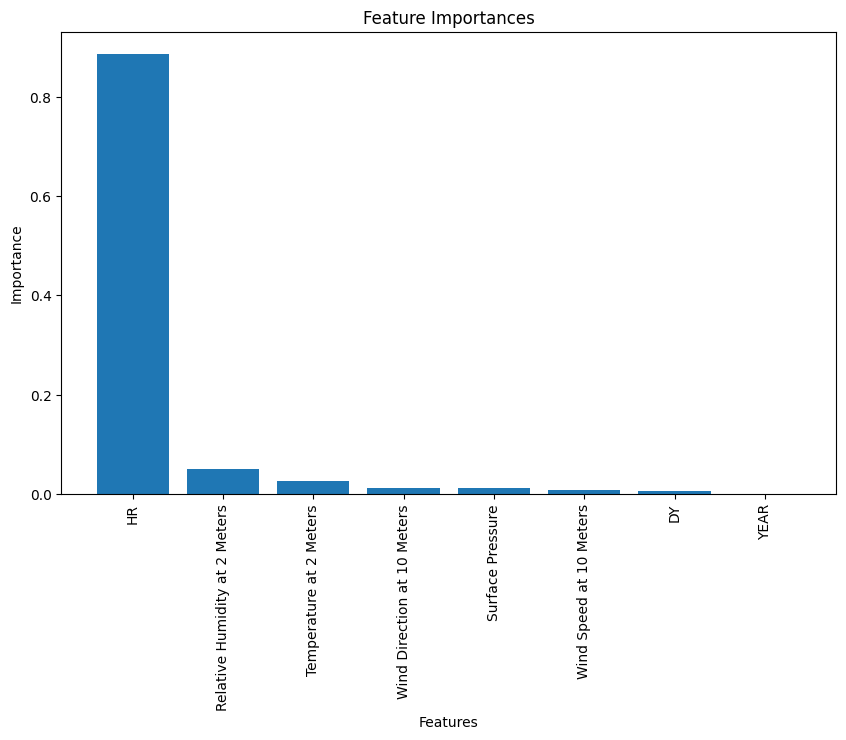

MSE: 3037.8174214608825
RMSE: 55.11639884336496
R2: 0.9718823128275846
MAE: 28.009688844621515


In [252]:
rf = RandomForestRegressor()
rf.fit(X_train, y_train)
importances = rf.feature_importances_
indices = np.argsort(importances)[::-1]
features = X.columns

plt.figure(figsize=(10, 6))
plt.title('Feature Importances')
plt.bar(range(X.shape[1]), importances[indices], align='center')
plt.xticks(range(X.shape[1]), [features[i] for i in indices], rotation=90)
plt.xlabel('Features')
plt.ylabel('Importance')
plt.show()
y_pred = rf.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f'MSE: {mse}')
print(f'RMSE: {rmse}')
print(f'R2: {r2}')
print(f'MAE: {mae}')

In [253]:
X_val, X_test, y_val, y_test = train_test_split(X_test, y_test, test_size=0.5, random_state=42)
print(X_train.shape, X_val.shape, X_test.shape)

(5270, 8) (1757, 8) (1757, 8)


In [254]:
X_train = np.expand_dims(X_train, axis=1)
X_test = np.expand_dims(X_test, axis=1)
X_val = np.expand_dims(X_val, axis=1)
model = tf.keras.models.Sequential([
    tf.keras.layers.Conv1D(64, 3, activation='relu',padding='same', input_shape=(X_train.shape[1], X_train.shape[2])),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(1, activation='linear'),
])

model.compile(optimizer='adam', loss='mse')

model.fit(X_train, y_train, epochs=10, batch_size=32, validation_data=(X_test, y_test))

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f"MSE: {mse}")
print(f"RMSE: {rmse}")
print(f"R2: {r2}")
print(f"MAE: {mae}")

Epoch 1/10


165/165 [==============================] - 2s 8ms/step - loss: 123338.9453 - val_loss: 105873.3906
Epoch 2/10
165/165 [==============================] - 1s 5ms/step - loss: 104925.5703 - val_loss: 98687.8438
Epoch 3/10
165/165 [==============================] - 1s 5ms/step - loss: 97420.0781 - val_loss: 91654.8281
Epoch 4/10
165/165 [==============================] - 1s 4ms/step - loss: 88846.5234 - val_loss: 82809.1875
Epoch 5/10
165/165 [==============================] - 1s 4ms/step - loss: 79834.1016 - val_loss: 74502.8125
Epoch 6/10
165/165 [==============================] - 1s 4ms/step - loss: 72342.1797 - val_loss: 68776.5938
Epoch 7/10
165/165 [==============================] - 1s 4ms/step - loss: 66363.7109 - val_loss: 64373.5781
Epoch 8/10
165/165 [==============================] - 1s 4ms/step - loss: 63331.2383 - val_loss: 61830.4766
Epoch 9/10
165/165 [==============================] - 1s 4ms/step - loss: 61106.9453 - val_loss: 61102.4961
Epoch 10/10
55/55 [=================

In [255]:
model_lstm = tf.keras.models.Sequential([
    tf.keras.layers.LSTM(32, activation='relu', input_shape=(X_train.shape[1], X_train.shape[2]), return_sequences=True),
    tf.keras.layers.Dense(1, activation='linear'),
])

model_lstm.compile(optimizer='adam', loss='mse')

model_lstm.fit(X_train, y_train, epochs=10, batch_size=32, validation_data=(X_test, y_test))

y_pred = model.predict(X_test)
y_pred = np.squeeze(y_pred)
y_pred = np.squeeze(y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f"MSE: {mse}")
print(f"RMSE: {rmse}")
print(f"R2: {r2}")
print(f"MAE: {mae}")

Epoch 1/10
165/165 [==============================] - 3s 10ms/step - loss: 116903.6641 - val_loss: 105781.9375
Epoch 2/10
165/165 [==============================] - 1s 8ms/step - loss: 106631.8203 - val_loss: 104388.1016
Epoch 3/10
165/165 [==============================] - 1s 9ms/step - loss: 105172.5234 - val_loss: 102769.6016
Epoch 4/10
165/165 [==============================] - 1s 8ms/step - loss: 103550.5156 - val_loss: 101148.8125
Epoch 5/10
165/165 [==============================] - 1s 8ms/step - loss: 101761.2109 - val_loss: 99274.3438
Epoch 6/10
165/165 [==============================] - 1s 8ms/step - loss: 99822.0703 - val_loss: 97342.0859
Epoch 7/10
165/165 [==============================] - 1s 8ms/step - loss: 97556.3047 - val_loss: 95737.9844
Epoch 8/10
165/165 [==============================] - 1s 8ms/step - loss: 95003.7500 - val_loss: 92989.2031
Epoch 9/10
165/165 [==============================] - 1s 8ms/step - loss: 92275.3516 - val_loss: 89679.4453
Epoch 10/10
55/55 

In [256]:
early_stopping = tf.keras.callbacks.EarlyStopping(patience=2, monitor='val_loss')

model_cnn_lstm = tf.keras.models.Sequential([
    tf.keras.layers.Conv1D(64, 3, activation='relu',padding='same', input_shape=(X_train.shape[1], X_train.shape[2])),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Flatten()),
    tf.keras.layers.LSTM(32, activation='relu', return_sequences=True),
    tf.keras.layers.Dense(1, activation='linear'),
])

model_cnn_lstm.compile(optimizer='adam', loss='mse')

model_cnn_lstm.fit(X_train, y_train, epochs=1000, batch_size=32, validation_data=(X_test, y_test), callbacks=[early_stopping])

y_pred = model.predict(X_test)
y_pred = np.squeeze(y_pred)
y_pred = np.squeeze(y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f"MSE: {mse}")
print(f"RMSE: {rmse}")
print(f"R2: {r2}")
print(f"MAE: {mae}")

Epoch 1/1000
165/165 [==============================] - 3s 11ms/step - loss: 118455.8125 - val_loss: 105623.9062
Epoch 2/1000
165/165 [==============================] - 2s 9ms/step - loss: 106517.8438 - val_loss: 102838.5469
Epoch 3/1000
165/165 [==============================] - 2s 9ms/step - loss: 102396.6719 - val_loss: 97681.5078
Epoch 4/1000
165/165 [==============================] - 2s 9ms/step - loss: 95220.2344 - val_loss: 89004.7031
Epoch 5/1000
165/165 [==============================] - 2s 9ms/step - loss: 81929.2812 - val_loss: 75579.8672
Epoch 6/1000
165/165 [==============================] - 2s 9ms/step - loss: 66701.7266 - val_loss: 70470.1562
Epoch 7/1000
165/165 [==============================] - 2s 9ms/step - loss: 60682.2617 - val_loss: 60118.6641
Epoch 8/1000
165/165 [==============================] - 2s 9ms/step - loss: 57391.3789 - val_loss: 56771.4883
Epoch 9/1000
165/165 [==============================] - 2s 9ms/step - loss: 55391.5039 - val_loss: 54557.4062
Epoc

### From 1/1/2024 to 1/2/2024 predictions

In [257]:
df_test = pd.read_csv('Test2_POWER_Point_Hourly_20240101_20240201_029d20N_032d62E_LST.csv')
df_test['All Sky Surface Shortwave Downward Irradiance'] = df_test['ALLSKY_SFC_SW_DWN']
df_test['Temperature at 2 Meters'] = df_test['T2M']
df_test['Relative Humidity at 2 Meters'] = df_test['RH2M']
df_test['Surface Pressure'] = df_test['PS']
df_test['Wind Speed at 10 Meters'] = df_test['WS10M']
df_test['Wind Direction at 10 Meters'] = df_test['WD10M']

df_test = df_test.drop(columns=['ALLSKY_SFC_SW_DWN', 'T2M', 'RH2M', 'PS', 'WS10M', 'WD10M'])
df_test = df_test.drop(columns=['MO'])
df_test.head()

,YEAR,DY,HR,All Sky Surface Shortwave Downward Irradiance,Temperature at 2 Meters,Relative Humidity at 2 Meters,Surface Pressure,Wind Speed at 10 Meters,Wind Direction at 10 Meters
0,2024,1,0,0.0,12.83,95.50,98.64,3.96,9.54
1,2024,1,1,0.0,12.87,96.31,98.63,3.78,9.40
2,2024,1,2,0.0,12.87,96.50,98.62,3.83,8.10
3,2024,1,3,0.0,12.83,97.19,98.61,4.01,8.51
4,2024,1,4,0.0,12.83,97.81,98.62,4.19,8.15


In [258]:
#list_prediction = []
#for i in range(len(df_test)):
#    prediction = rf.predict([df_test.drop(columns="All Sky Surface Shortwave Downward Irradiance").iloc[i]])
#    list_prediction.append(prediction[0])

y_pred_lr = lr.predict(df_test.drop(columns="All Sky Surface Shortwave Downward Irradiance"))
y_pred_gb = gb.predict(df_test.drop(columns="All Sky Surface Shortwave Downward Irradiance"))
y_pred_dt = dt.predict(df_test.drop(columns="All Sky Surface Shortwave Downward Irradiance"))
y_pred_rf = rf.predict(df_test.drop(columns="All Sky Surface Shortwave Downward Irradiance"))
y_pred_cnn = model.predict(np.expand_dims(df_test.drop(columns="All Sky Surface Shortwave Downward Irradiance"), axis=1))
y_pred_lstm = model_lstm.predict(np.expand_dims(df_test.drop(columns="All Sky Surface Shortwave Downward Irradiance"), axis=1))
y_pred_cnn_lstm = model_cnn_lstm.predict(np.expand_dims(df_test.drop(columns="All Sky Surface Shortwave Downward Irradiance"), axis=1))
y_pred_cnn = np.squeeze(y_pred_cnn)
y_pred_lstm = np.squeeze(y_pred_lstm)
y_pred_cnn_lstm = np.squeeze(y_pred_cnn_lstm)
y_pred_cnn_lstm = np.squeeze(y_pred_cnn_lstm)

pred = [y_pred_lr, y_pred_gb, y_pred_dt, y_pred_rf, y_pred_cnn, y_pred_lstm, y_pred_cnn_lstm]
for i in range(len(pred)):
    r2 = r2_score(df_test['All Sky Surface Shortwave Downward Irradiance'], pred[i])
    mse = mean_squared_error(df_test['All Sky Surface Shortwave Downward Irradiance'], pred[i])
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(df_test['All Sky Surface Shortwave Downward Irradiance'], pred[i])
    print(f"R2 {i}: {r2}")
    print(f"MSE {i}: {mse}")
    print(f"RMSE {i}: {rmse}")
    print(f"MAE {i}: {mae}")


#df_test['Predicted All Sky Surface Shortwave Downward Irradiance'] = list_prediction
#df_test['Actuall All Sky Surface Shortwave Downward Irradiance'] = df_test['All Sky Surface Shortwave Downward Irradiance']
#df_test = df_test.drop(columns='All Sky Surface Shortwave Downward Irradiance')
#df_test.to_csv('DecisionTree_Predicted_POWER.csv', index=False)

24/24 [==============================] - 0s 2ms/step
R2 0: 0.3301816234442211
MSE 0: 38098.65730760691
RMSE 0: 195.18877351837352
MAE 0: 159.23078359019541
R2 1: 0.5334506754511221
MSE 1: 26536.899337522093
RMSE 1: 162.9015019498657
MAE 1: 107.55836407752945
R2 2: 0.5143423362837003
MSE 2: 27623.76421184896
RMSE 2: 166.20398374241503
MAE 2: 103.82959635416667
R2 3: 0.5698973003262275
MSE 3: 24463.848612524685
RMSE 3: 156.40923442215515
MAE 3: 97.34471588541665
R2 4: 0.4439182935736087
MSE 4: 31629.419421287104
RMSE 4: 177.84661768301106
MAE 4: 138.71073373183958
R2 5: 0.15555811658799157
MSE 5: 48031.082840297575
RMSE 5: 219.15994807513889
MAE 5: 203.30700385650002
R2 6: 0.4058812088252026
MSE 6: 33792.934050822274
RMSE 6: 183.8285452556873
MAE 6: 138.10240748473132
